ALIP — MODULE 1: RESEARCH-GRADE DEMAND FORECASTING

Configuration loaded.


STEP 1 — FINDING KAGGLE COMPETITION DATA

Files found:
✓ train.csv.zip -> /kaggle/input/competitions/walmart-recruiting-store-sales-forecasting/train.csv.zip
✓ sampleSubmission.csv.zip -> /kaggle/input/competitions/walmart-recruiting-store-sales-forecasting/sampleSubmission.csv.zip
✓ features.csv.zip -> /kaggle/input/competitions/walmart-recruiting-store-sales-forecasting/features.csv.zip
✓ test.csv.zip -> /kaggle/input/competitions/walmart-recruiting-store-sales-forecasting/test.csv.zip
✓ stores.csv -> /kaggle/input/competitions/walmart-recruiting-store-sales-forecasting/stores.csv


STEP 2 — EXTRACTING DATA

Extracting: train.csv.zip

Extracting: sampleSubmission.csv.zip

Extracting: features.csv.zip

Extracting: test.csv.zip

Extraction complete.

Extracted data:
train.csv    -> /kaggle/working/ALIP_Walmart_Data/train.csv
features.csv -> /kaggle/working/ALIP_Walmart_Data/features.csv
test.csv     -> /kaggle/

2026-10-08 11:19:52.102317: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/20
893/893 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - loss: 0.1572 - mae: 0.1887 - val_loss: 0.0638 - val_mae: 0.1670 - learning_rate: 0.0010
Epoch 2/20
893/893 ━━━━━━━━━━━━━━━━━━━━ 37s 41ms/step - loss: 0.1190 - mae: 0.1578 - val_loss: 0.0934 - val_mae: 0.1904 - learning_rate: 0.0010
Epoch 3/20
893/893 ━━━━━━━━━━━━━━━━━━━━ 36s 41ms/step - loss: 0.1085 - mae: 0.1518 - val_loss: 0.0957 - val_mae: 0.1749 - learning_rate: 0.0010
Epoch 4/20
893/893 ━━━━━━━━━━━━━━━━━━━━ 37s 42ms/step - loss: 0.0929 - mae: 0.1453 - val_loss: 0.0742 - val_mae: 0.1513 - learning_rate: 5.0000e-04
Epoch 5/20
893/893 ━━━━━━━━━━━━━━━━━━━━ 38s 42ms/step - loss: 0.0870 - mae: 0.1435 - val_loss: 0.1171 - val_mae: 0.2111 - learning_rate: 5.0000e-04
Validation RMSE: 5776.8644

Training LSTM_B
Epoch 1/20
893/893 ━━━━━━━━━━━━━━━━━━━━ 76s 81ms/step - loss: 0.1443 - mae: 0.1777 - val_loss: 0.0859 - val_mae: 0.1819 - learning_rate: 0.0010
Epoch 2/20
893/893 ━━━━━━━━━━━━━━━━━━━━ 72s 80ms/step - loss: 0.1069 - mae: 0.1507 -

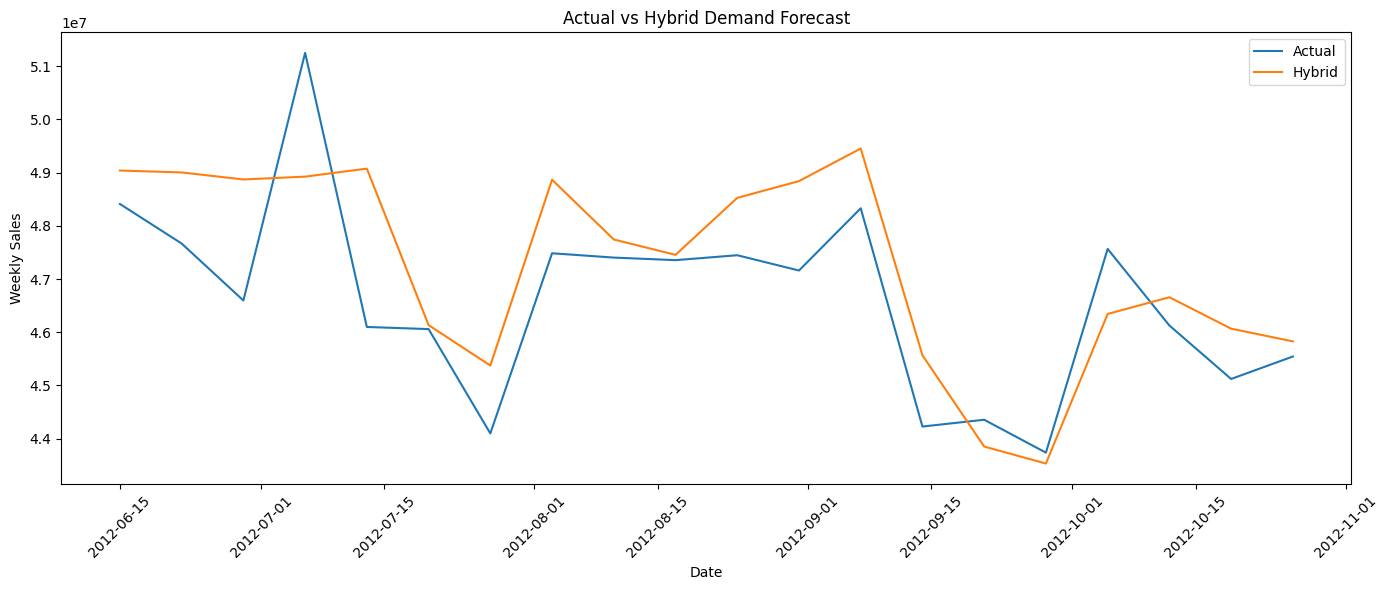

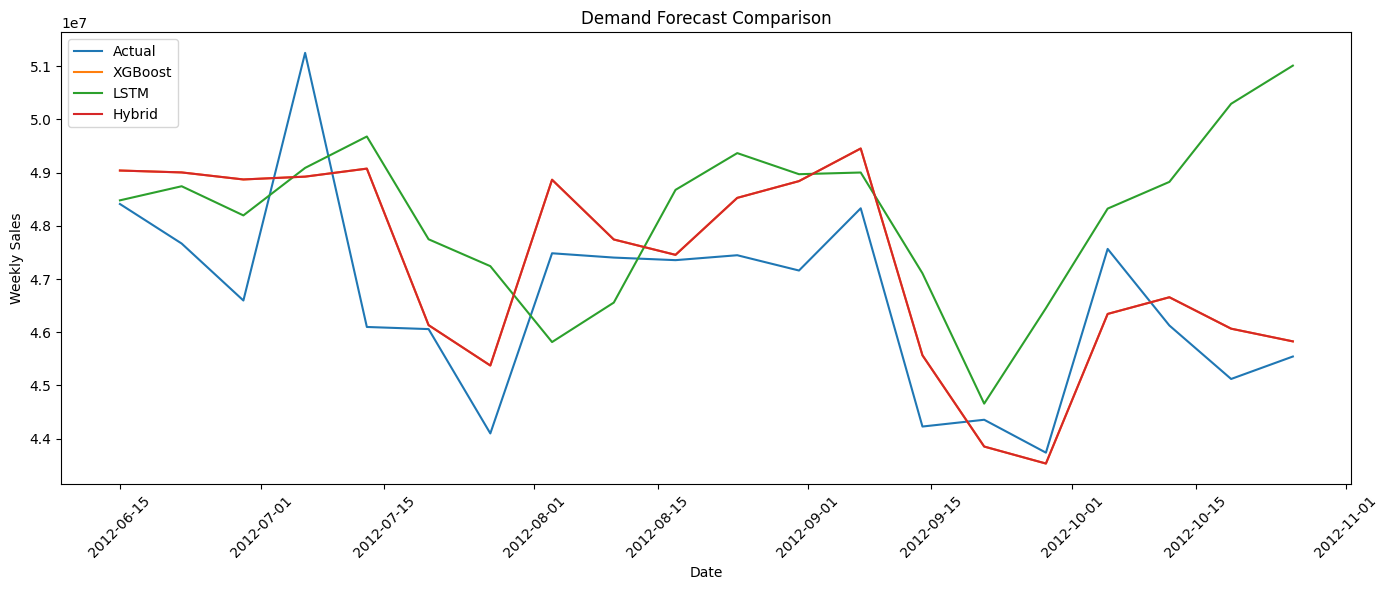

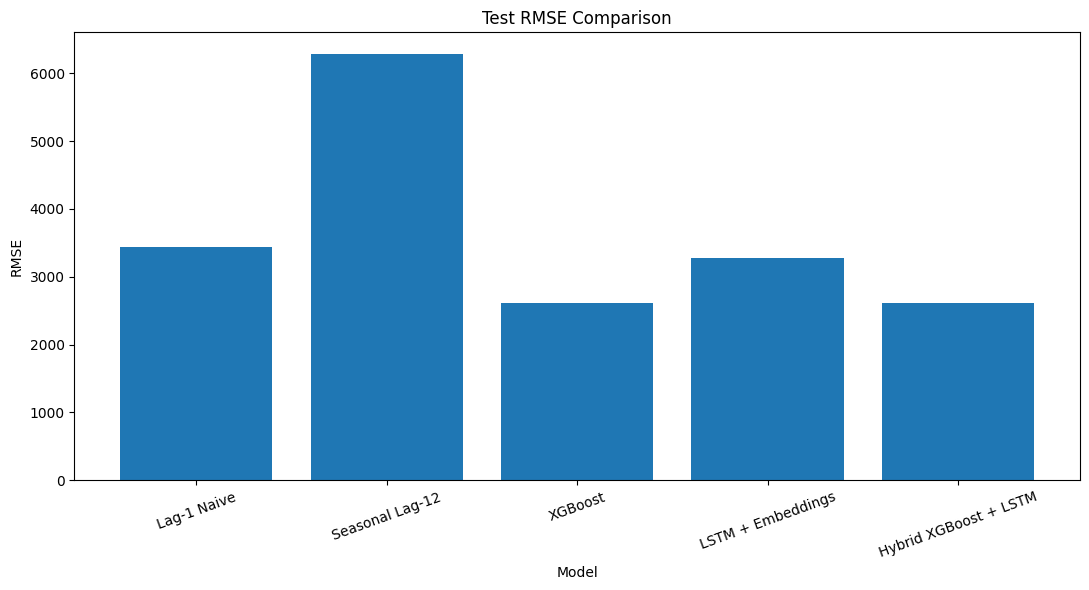

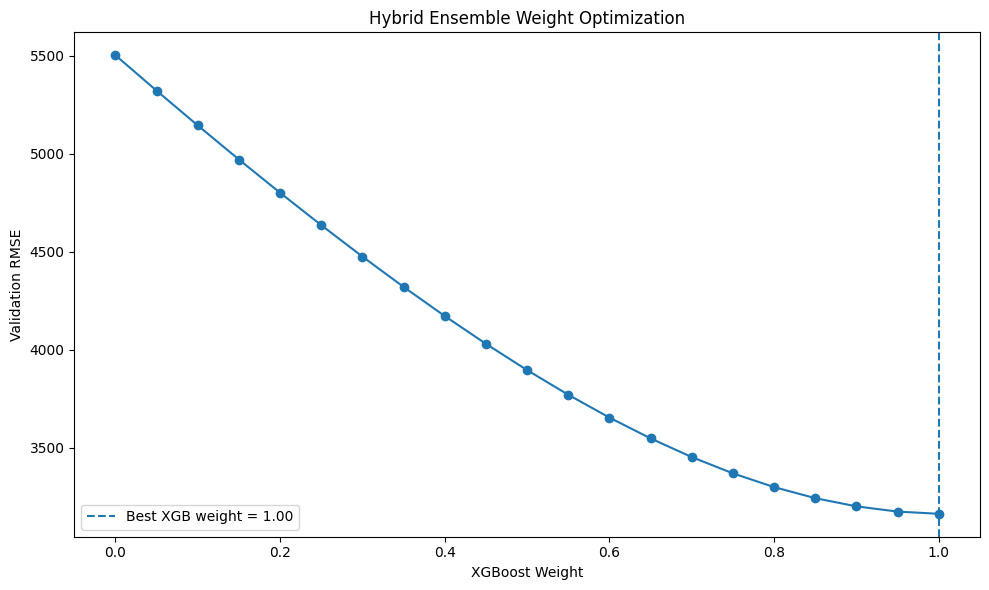

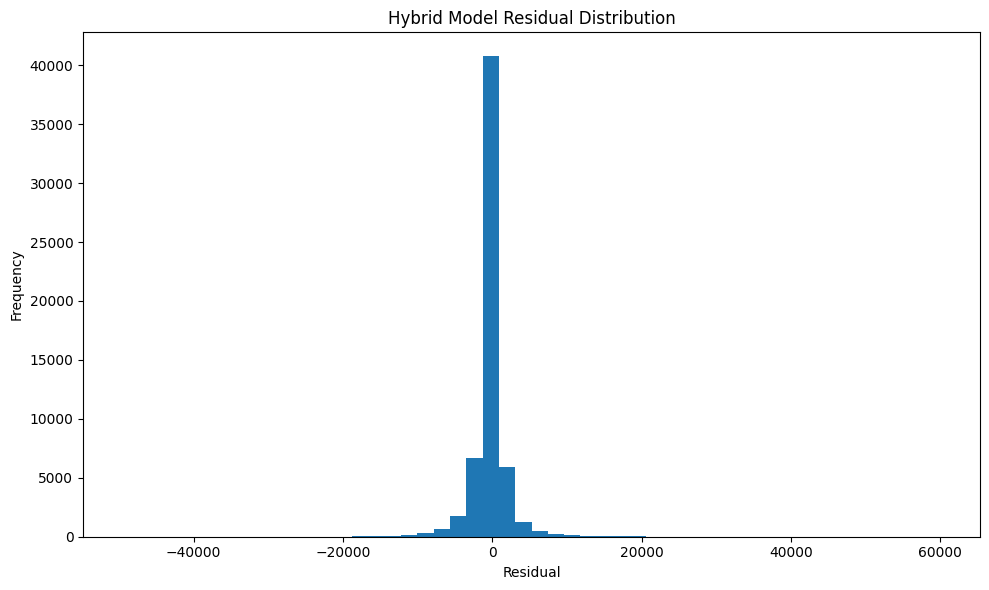

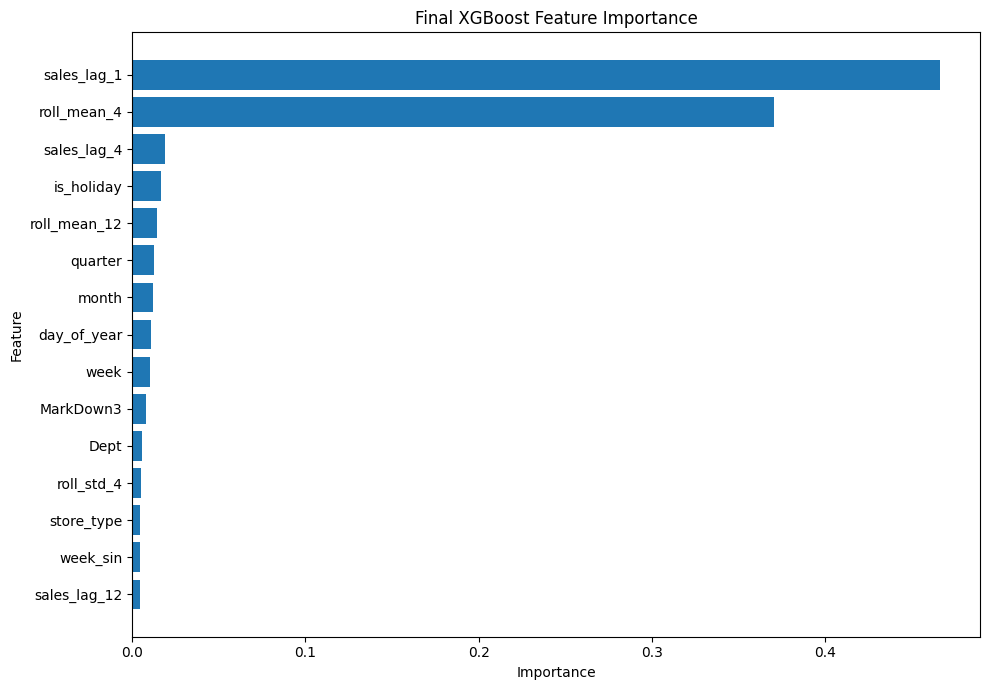


Saved final XGBoost: /kaggle/working/ALIP_Demand_Models/demand_xgb.json
Saved final LSTM: /kaggle/working/ALIP_Demand_Models/demand_lstm.keras
Saved preprocessing: /kaggle/working/ALIP_Demand_Models/demand_lstm_preprocessing.pkl


STEP 19 — PACKAGING ALIP MODEL


ALIP MODULE 1 — COMPLETE

FINAL MODEL COMPARISON
                Model         MAE        RMSE    MAPE (%)  WAPE (%)       R2
          Lag-1 Naive 1533.633461 3439.704826  132.102840  9.671530 0.975529
      Seasonal Lag-12 2884.472352 6286.816780 3975.391881 18.190306 0.918253
              XGBoost 1259.501726 2611.797865  834.825981  7.942777 0.985891
    LSTM + Embeddings 1788.858840 3269.755177 1557.846514 11.281054 0.977887
Hybrid XGBoost + LSTM 1259.501726 2611.797865  834.825981  7.942777 0.985891


BEST MODEL:
XGBoost
TEST RMSE: 2611.7979


HYBRID WEIGHTS
XGBoost: 1.0
LSTM: 0.0


FINAL MODEL PACKAGE:
/kaggle/working/ALIP_Demand_Models.zip

Generated model files:
✓ hybrid_weight_search.csv
✓ dataset_info.json
✓ lstm_c

In [2]:
# ============================================================
# ============================================================
#
#        ALIP — MODULE 1
#        RESEARCH-GRADE DEMAND FORECASTING
#
#        Dataset:
#        Walmart Recruiting - Store Sales Forecasting
#
#        Models:
#        1. Lag-1 Naive Baseline
#        2. Seasonal Naive Baseline
#        3. Tuned XGBoost
#        4. Multivariate LSTM + Store Embedding
#           + Department Embedding
#        5. Hybrid XGBoost + LSTM
#
#        IMPORTANT:
#        - Time-series split
#        - Leakage-safe preprocessing
#        - Validation-based model selection
#        - Validation-based hybrid weighting
#        - Final evaluation on untouched test set
#
#        OUTPUT:
#        /kaggle/working/ALIP_Demand_Models.zip
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import zipfile
import json
import pickle
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 42

np.random.seed(SEED)


print("=" * 80)
print("ALIP — MODULE 1: RESEARCH-GRADE DEMAND FORECASTING")
print("=" * 80)


# ============================================================
# 1. CONFIGURATION
# ============================================================

INPUT_ROOT = "/kaggle/input"

EXTRACT_ROOT = (
    "/kaggle/working/"
    "ALIP_Walmart_Data"
)

OUTPUT_ROOT = (
    "/kaggle/working/"
    "ALIP_Demand_Models"
)

PLOTS_DIR = os.path.join(
    OUTPUT_ROOT,
    "plots"
)

os.makedirs(
    EXTRACT_ROOT,
    exist_ok=True
)

os.makedirs(
    OUTPUT_ROOT,
    exist_ok=True
)

os.makedirs(
    PLOTS_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# Time-series split
# ------------------------------------------------------------

TRAIN_RATIO = 0.70

VALIDATION_RATIO = 0.15

TEST_RATIO = 0.15


# ------------------------------------------------------------
# LSTM
# ------------------------------------------------------------

LSTM_WINDOW = 12

LSTM_BATCH_SIZE = 256

LSTM_TUNING_EPOCHS = 20


# ------------------------------------------------------------
# Random seed
# ------------------------------------------------------------

np.random.seed(SEED)


print("\nConfiguration loaded.")


# ============================================================
# 2. FIND KAGGLE COMPETITION DATA
# ============================================================

print("\n")
print("=" * 80)
print("STEP 1 — FINDING KAGGLE COMPETITION DATA")
print("=" * 80)


zip_files = {}

stores_path = None


for root, dirs, files in os.walk(
    INPUT_ROOT
):

    for file in files:

        full_path = os.path.join(
            root,
            file
        )


        if file in [

            "train.csv.zip",

            "features.csv.zip",

            "test.csv.zip",

            "sampleSubmission.csv.zip"

        ]:

            zip_files[file] = full_path


        elif file == "stores.csv":

            stores_path = full_path


print("\nFiles found:")


for name, path in zip_files.items():

    print(
        "✓",
        name,
        "->",
        path
    )


if stores_path:

    print(
        "✓ stores.csv ->",
        stores_path
    )


if "train.csv.zip" not in zip_files:

    raise FileNotFoundError(
        "train.csv.zip was not found."
    )


if "features.csv.zip" not in zip_files:

    raise FileNotFoundError(
        "features.csv.zip was not found."
    )


if stores_path is None:

    raise FileNotFoundError(
        "stores.csv was not found."
    )


# ============================================================
# 3. EXTRACT ZIP FILES
# ============================================================

print("\n")
print("=" * 80)
print("STEP 2 — EXTRACTING DATA")
print("=" * 80)


for name, path in zip_files.items():

    print(
        "\nExtracting:",
        name
    )

    with zipfile.ZipFile(
        path,
        "r"
    ) as z:

        z.extractall(
            EXTRACT_ROOT
        )


print(
    "\nExtraction complete."
)


# ============================================================
# 4. FIND EXTRACTED FILES
# ============================================================

train_path = None

features_path = None

test_path = None


for root, dirs, files in os.walk(
    EXTRACT_ROOT
):

    for file in files:

        full_path = os.path.join(
            root,
            file
        )


        if file == "train.csv":

            train_path = full_path


        elif file == "features.csv":

            features_path = full_path


        elif file == "test.csv":

            test_path = full_path


if train_path is None:

    raise FileNotFoundError(
        "train.csv could not be extracted."
    )


if features_path is None:

    raise FileNotFoundError(
        "features.csv could not be extracted."
    )


print("\nExtracted data:")

print(
    "train.csv    ->",
    train_path
)

print(
    "features.csv ->",
    features_path
)

print(
    "test.csv     ->",
    test_path
)

print(
    "stores.csv   ->",
    stores_path
)


# ============================================================
# 5. LOAD DATA
# ============================================================

print("\n")
print("=" * 80)
print("STEP 3 — LOADING DATA")
print("=" * 80)


train = pd.read_csv(

    train_path,

    parse_dates=[
        "Date"
    ]

)


features = pd.read_csv(

    features_path,

    parse_dates=[
        "Date"
    ]

)


stores = pd.read_csv(
    stores_path
)


print("\nDataset shapes:")

print(
    "train.csv    :",
    train.shape
)

print(
    "features.csv :",
    features.shape
)

print(
    "stores.csv   :",
    stores.shape
)


# ============================================================
# 6. MERGE DATA
# ============================================================

print("\n")
print("=" * 80)
print("STEP 4 — MERGING DATA")
print("=" * 80)


df = train.merge(

    features,

    on=[
        "Store",
        "Date",
        "IsHoliday"
    ],

    how="left"

)


df = df.merge(

    stores,

    on="Store",

    how="left"

)


duplicate_count = (

    df
    .duplicated(
        subset=[
            "Store",
            "Dept",
            "Date"
        ]
    )
    .sum()

)


if duplicate_count > 0:

    raise ValueError(
        "Duplicate Store/Dept/Date rows detected."
    )


df = df.sort_values(

    [
        "Store",
        "Dept",
        "Date"
    ]

).reset_index(
    drop=True
)


print(
    "\nMerged dataframe:",
    df.shape
)


# ============================================================
# 7. HANDLE MARKDOWN VALUES
# ============================================================

print("\n")
print("=" * 80)
print("STEP 5 — DATA CLEANING")
print("=" * 80)


markdown_columns = [

    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"

]


for column in markdown_columns:

    if column in df.columns:

        df[column] = (
            df[column]
            .fillna(0)
        )


# ============================================================
# 8. CALENDAR FEATURES
# ============================================================

print("\nCreating calendar features...")


df["year"] = (
    df["Date"]
    .dt.year
)


df["month"] = (
    df["Date"]
    .dt.month
)


df["quarter"] = (
    df["Date"]
    .dt.quarter
)


df["day_of_year"] = (
    df["Date"]
    .dt.dayofyear
)


df["week"] = (

    df["Date"]
    .dt.isocalendar()
    .week
    .astype(int)

)


# ------------------------------------------------------------
# Cyclic weekly encoding
# ------------------------------------------------------------

df["week_sin"] = (

    np.sin(

        2
        *
        np.pi
        *
        df["week"]
        /
        52

    )

)


df["week_cos"] = (

    np.cos(

        2
        *
        np.pi
        *
        df["week"]
        /
        52

    )

)


# ------------------------------------------------------------
# Cyclic monthly encoding
# ------------------------------------------------------------

df["month_sin"] = (

    np.sin(

        2
        *
        np.pi
        *
        df["month"]
        /
        12

    )

)


df["month_cos"] = (

    np.cos(

        2
        *
        np.pi
        *
        df["month"]
        /
        12

    )

)


# Holiday

df["is_holiday"] = (

    df["IsHoliday"]
    .astype(int)

)


# Store type

df["store_type"] = (

    df["Type"]
    .map({

        "A": 0,

        "B": 1,

        "C": 2

    })

    .fillna(-1)

    .astype(int)

)


# ============================================================
# 9. SORT DATA
# ============================================================

df = df.sort_values(

    [
        "Store",
        "Dept",
        "Date"
    ]

).reset_index(
    drop=True
)


# ============================================================
# 10. LAG FEATURES
# ============================================================

print(
    "Creating lag features..."
)


group = [

    "Store",
    "Dept"

]


df["sales_lag_1"] = (

    df
    .groupby(group)
    ["Weekly_Sales"]
    .shift(1)

)


df["sales_lag_4"] = (

    df
    .groupby(group)
    ["Weekly_Sales"]
    .shift(4)

)


df["sales_lag_12"] = (

    df
    .groupby(group)
    ["Weekly_Sales"]
    .shift(12)

)


# ============================================================
# 11. ROLLING FEATURES
#
# IMPORTANT:
# shift(1) occurs BEFORE rolling.
#
# Therefore current week's sales never enters its own
# features.
# ============================================================

df["roll_mean_4"] = (

    df
    .groupby(group)
    ["Weekly_Sales"]
    .transform(

        lambda x:
        x.shift(1)
        .rolling(4)
        .mean()

    )

)


df["roll_mean_12"] = (

    df
    .groupby(group)
    ["Weekly_Sales"]
    .transform(

        lambda x:
        x.shift(1)
        .rolling(12)
        .mean()

    )

)


df["roll_std_4"] = (

    df
    .groupby(group)
    ["Weekly_Sales"]
    .transform(

        lambda x:
        x.shift(1)
        .rolling(4)
        .std()

    )

)


# ============================================================
# 12. REMOVE INSUFFICIENT-HISTORY ROWS
# ============================================================

history_columns = [

    "sales_lag_1",

    "sales_lag_4",

    "sales_lag_12",

    "roll_mean_4",

    "roll_mean_12",

    "roll_std_4"

]


before = len(df)


df = df.dropna(

    subset=history_columns

).reset_index(
    drop=True
)


print(

    "\nRows removed:",

    before - len(df)

)


print(

    "Rows remaining:",

    len(df)

)


# ============================================================
# 13. CHRONOLOGICAL SPLIT
# ============================================================

print("\n")
print("=" * 80)
print("STEP 6 — CHRONOLOGICAL TRAIN / VALIDATION / TEST")
print("=" * 80)


unique_dates = np.array(

    sorted(
        df["Date"]
        .unique()
    )

)


n_dates = len(
    unique_dates
)


train_cut = int(

    n_dates
    *
    TRAIN_RATIO

)


validation_cut = int(

    n_dates
    *
    (
        TRAIN_RATIO
        +
        VALIDATION_RATIO
    )

)


train_end_date = (
    unique_dates[
        train_cut
    ]
)


validation_end_date = (
    unique_dates[
        validation_cut
    ]
)


train_df = df[

    df["Date"]
    <
    train_end_date

].copy()


validation_df = df[

    (
        df["Date"]
        >=
        train_end_date
    )

    &

    (
        df["Date"]
        <
        validation_end_date
    )

].copy()


test_df = df[

    df["Date"]
    >=
    validation_end_date

].copy()


print("\nTRAIN")

print(
    train_df["Date"].min(),
    "→",
    train_df["Date"].max()
)

print(
    "Rows:",
    len(train_df)
)


print("\nVALIDATION")

print(
    validation_df["Date"].min(),
    "→",
    validation_df["Date"].max()
)

print(
    "Rows:",
    len(validation_df)
)


print("\nTEST")

print(
    test_df["Date"].min(),
    "→",
    test_df["Date"].max()
)

print(
    "Rows:",
    len(test_df)
)


# ============================================================
# 14. TRAINING-ONLY IMPUTATION VALUES
# ============================================================

imputation_columns = [

    "Temperature",

    "Fuel_Price",

    "CPI",

    "Unemployment",

    "Size"

]


training_medians = {}


for column in imputation_columns:

    median = (

        train_df[column]
        .median()

    )


    training_medians[column] = float(
        median
    )


    train_df[column] = (

        train_df[column]
        .fillna(median)

    )


    validation_df[column] = (

        validation_df[column]
        .fillna(median)

    )


    test_df[column] = (

        test_df[column]
        .fillna(median)

    )


# Apply same values to full dataframe
# for LSTM sequence construction.

for column, value in training_medians.items():

    df[column] = (

        df[column]
        .fillna(value)

    )


# ============================================================
# 15. METRIC FUNCTIONS
# ============================================================

from sklearn.metrics import (

    mean_absolute_error,

    mean_squared_error,

    r2_score

)


def metrics(
    actual,
    predicted
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    predicted = np.asarray(
        predicted,
        dtype=float
    )


    mae = mean_absolute_error(

        actual,

        predicted

    )


    rmse = np.sqrt(

        mean_squared_error(

            actual,

            predicted

        )

    )


    r2 = r2_score(

        actual,

        predicted

    )


    nonzero = (
        actual != 0
    )


    if np.any(nonzero):

        mape = (

            np.mean(

                np.abs(

                    (
                        actual[nonzero]
                        -
                        predicted[nonzero]
                    )
                    /
                    actual[nonzero]

                )

            )

            *

            100

        )

    else:

        mape = np.nan


    denominator = np.sum(
        np.abs(actual)
    )


    if denominator > 0:

        wape = (

            np.sum(

                np.abs(

                    actual
                    -
                    predicted

                )

            )

            /

            denominator

        ) * 100

    else:

        wape = np.nan


    return {

        "MAE":
            float(mae),

        "RMSE":
            float(rmse),

        "MAPE":
            float(mape),

        "WAPE":
            float(wape),

        "R2":
            float(r2)

    }


# ============================================================
# 16. BASELINES
# ============================================================

print("\n")
print("=" * 80)
print("STEP 7 — BASELINE MODELS")
print("=" * 80)


# ------------------------------------------------------------
# Lag-1 baseline
# ------------------------------------------------------------

lag1_actual = (
    test_df["Weekly_Sales"]
    .values
)

lag1_prediction = (
    test_df["sales_lag_1"]
    .values
)


lag1_metrics = metrics(

    lag1_actual,

    lag1_prediction

)


# ------------------------------------------------------------
# Seasonal baseline
# ------------------------------------------------------------

seasonal_prediction = (
    test_df["sales_lag_12"]
    .values
)


seasonal_metrics = metrics(

    lag1_actual,

    seasonal_prediction

)


print("\nLag-1 Baseline:")

for k, v in lag1_metrics.items():

    print(
        f"{k}: {v:.4f}"
    )


print("\nSeasonal Lag-12 Baseline:")

for k, v in seasonal_metrics.items():

    print(
        f"{k}: {v:.4f}"
    )


# ============================================================
# 17. XGBOOST FEATURES
# ============================================================

XGB_FEATURES = [

    "Store",

    "Dept",

    "store_type",

    "Size",

    "is_holiday",

    "Temperature",

    "Fuel_Price",

    "CPI",

    "Unemployment",

    "MarkDown1",

    "MarkDown2",

    "MarkDown3",

    "MarkDown4",

    "MarkDown5",

    "year",

    "month",

    "quarter",

    "day_of_year",

    "week",

    "week_sin",

    "week_cos",

    "month_sin",

    "month_cos",

    "sales_lag_1",

    "sales_lag_4",

    "sales_lag_12",

    "roll_mean_4",

    "roll_mean_12",

    "roll_std_4"

]


TARGET = "Weekly_Sales"


# ============================================================
# 18. XGBOOST DATA
# ============================================================

X_train = train_df[
    XGB_FEATURES
].copy()


y_train = train_df[
    TARGET
].copy()


X_val = validation_df[
    XGB_FEATURES
].copy()


y_val = validation_df[
    TARGET
].copy()


X_test = test_df[
    XGB_FEATURES
].copy()


y_test = test_df[
    TARGET
].copy()


# ============================================================
# 19. XGBOOST HYPERPARAMETER SEARCH
# ============================================================

print("\n")
print("=" * 80)
print("STEP 8 — XGBOOST HYPERPARAMETER SEARCH")
print("=" * 80)


from xgboost import XGBRegressor


xgb_configs = [

    {

        "name": "XGB_A",

        "n_estimators": 600,

        "max_depth": 6,

        "learning_rate": 0.04,

        "min_child_weight": 3,

        "subsample": 0.80,

        "colsample_bytree": 0.80,

        "reg_alpha": 0.0,

        "reg_lambda": 1.0

    },

    {

        "name": "XGB_B",

        "n_estimators": 800,

        "max_depth": 8,

        "learning_rate": 0.03,

        "min_child_weight": 3,

        "subsample": 0.80,

        "colsample_bytree": 0.80,

        "reg_alpha": 0.10,

        "reg_lambda": 1.0

    },

    {

        "name": "XGB_C",

        "n_estimators": 1000,

        "max_depth": 10,

        "learning_rate": 0.02,

        "min_child_weight": 5,

        "subsample": 0.85,

        "colsample_bytree": 0.85,

        "reg_alpha": 0.10,

        "reg_lambda": 2.0

    }

]


xgb_search_results = []

best_xgb_config = None

best_xgb_val_rmse = float("inf")


for config in xgb_configs:

    print(
        "\nTraining",
        config["name"]
    )


    model = XGBRegressor(

        n_estimators=
            config["n_estimators"],

        max_depth=
            config["max_depth"],

        learning_rate=
            config["learning_rate"],

        min_child_weight=
            config["min_child_weight"],

        subsample=
            config["subsample"],

        colsample_bytree=
            config["colsample_bytree"],

        reg_alpha=
            config["reg_alpha"],

        reg_lambda=
            config["reg_lambda"],

        objective=
            "reg:squarederror",

        eval_metric=
            "rmse",

        random_state=
            SEED,

        n_jobs=
            -1

    )


    model.fit(

        X_train,

        y_train,

        eval_set=[

            (
                X_val,
                y_val
            )

        ],

        verbose=False

    )


    val_prediction = model.predict(
        X_val
    )


    val_prediction = np.maximum(
        val_prediction,
        0
    )


    result = metrics(

        y_val,

        val_prediction

    )


    xgb_search_results.append({

        "Model":
            config["name"],

        "RMSE":
            result["RMSE"],

        "MAE":
            result["MAE"],

        "WAPE":
            result["WAPE"]

    })


    print(

        "Validation RMSE:",

        round(
            result["RMSE"],
            4
        )

    )


    if result["RMSE"] < best_xgb_val_rmse:

        best_xgb_val_rmse = result["RMSE"]

        best_xgb_config = config.copy()


print("\nBest XGBoost configuration:")

print(
    best_xgb_config
)


xgb_search_df = pd.DataFrame(
    xgb_search_results
)


xgb_search_df.to_csv(

    os.path.join(

        OUTPUT_ROOT,

        "xgboost_hyperparameter_search.csv"

    ),

    index=False

)


# ============================================================
# 20. TRAIN SELECTED XGBOOST ON TRAIN ONLY
#
# This model is used for validation-based hybrid weight
# selection.
# ============================================================

print("\n")
print("=" * 80)
print("STEP 9 — TRAINING SELECTED XGBOOST")
print("=" * 80)


xgb_validation_model = XGBRegressor(

    n_estimators=
        best_xgb_config["n_estimators"],

    max_depth=
        best_xgb_config["max_depth"],

    learning_rate=
        best_xgb_config["learning_rate"],

    min_child_weight=
        best_xgb_config["min_child_weight"],

    subsample=
        best_xgb_config["subsample"],

    colsample_bytree=
        best_xgb_config["colsample_bytree"],

    reg_alpha=
        best_xgb_config["reg_alpha"],

    reg_lambda=
        best_xgb_config["reg_lambda"],

    objective=
        "reg:squarederror",

    eval_metric=
        "rmse",

    random_state=
        SEED,

    n_jobs=
        -1

)


xgb_validation_model.fit(

    X_train,

    y_train,

    verbose=False

)


xgb_val_prediction = (

    xgb_validation_model
    .predict(X_val)

)


xgb_val_prediction = np.maximum(

    xgb_val_prediction,

    0

)


# ============================================================
# 21. LSTM PREPARATION
# ============================================================

print("\n")
print("=" * 80)
print("STEP 10 — PREPARING GLOBAL MULTIVARIATE LSTM")
print("=" * 80)


LSTM_FEATURES = [

    "Weekly_Sales",

    "Temperature",

    "Fuel_Price",

    "CPI",

    "Unemployment",

    "MarkDown1",

    "MarkDown2",

    "MarkDown3",

    "MarkDown4",

    "MarkDown5",

    "is_holiday",

    "week_sin",

    "week_cos",

    "month_sin",

    "month_cos"

]


print("\nLSTM sequence features:")

for feature in LSTM_FEATURES:

    print(
        "✓",
        feature
    )


# ============================================================
# 22. STORE / DEPARTMENT MAPPINGS
# ============================================================

all_stores = sorted(
    df["Store"]
    .unique()
)

all_departments = sorted(
    df["Dept"]
    .unique()
)


store_to_id = {

    int(store):
        idx

    for idx, store
    in enumerate(all_stores)

}


dept_to_id = {

    int(dept):
        idx

    for idx, dept
    in enumerate(all_departments)

}


print(

    "\nStores:",
    len(store_to_id)

)

print(

    "Departments:",
    len(dept_to_id)

)


# ============================================================
# 23. SCALING
#
# Global scaler is fitted ONLY on training data.
# ============================================================

from sklearn.preprocessing import StandardScaler


feature_scaler = StandardScaler()

target_scaler = StandardScaler()


feature_scaler.fit(

    train_df[
        LSTM_FEATURES
    ]

)


target_scaler.fit(

    train_df[
        [
            "Weekly_Sales"
        ]
    ]

)


# ============================================================
# 24. LSTM SEQUENCE CREATION FUNCTION
# ============================================================

def create_lstm_sequences(

    data,

    feature_scaler,

    target_scaler,

    window,

    target_start_date=None,

    target_end_date=None

):

    sequence_X = []

    sequence_y = []

    store_ids = []

    dept_ids = []

    records = []


    for (

        store,

        dept

    ), group_data in data.groupby(

        [
            "Store",
            "Dept"
        ]

    ):

        group_data = (

            group_data
            .sort_values(
                "Date"
            )
            .reset_index(
                drop=True
            )

        )


        if len(group_data) <= window:

            continue


        scaled_features = (

            feature_scaler
            .transform(

                group_data[
                    LSTM_FEATURES
                ]

            )

        )


        scaled_target = (

            target_scaler
            .transform(

                group_data[
                    [
                        "Weekly_Sales"
                    ]
                ]

            )
            .flatten()

        )


        dates = group_data[
            "Date"
        ].values


        for i in range(

            window,

            len(group_data)

        ):

            target_date = dates[i]


            if (

                target_start_date
                is not None
                and
                target_date
                <
                target_start_date

            ):

                continue


            if (

                target_end_date
                is not None
                and
                target_date
                >=
                target_end_date

            ):

                continue


            sequence_X.append(

                scaled_features[
                    i - window:i
                ]

            )


            sequence_y.append(

                scaled_target[i]

            )


            store_ids.append(

                store_to_id[
                    int(store)
                ]

            )


            dept_ids.append(

                dept_to_id[
                    int(dept)
                ]

            )


            records.append({

                "Store":
                    int(store),

                "Dept":
                    int(dept),

                "Date":
                    pd.Timestamp(
                        target_date
                    )

            })


    return (

        np.asarray(
            sequence_X,
            dtype=np.float32
        ),

        np.asarray(
            sequence_y,
            dtype=np.float32
        ),

        np.asarray(
            store_ids,
            dtype=np.int32
        ),

        np.asarray(
            dept_ids,
            dtype=np.int32
        ),

        records

    )


# ============================================================
# 25. CREATE TRAIN / VALIDATION / TEST SEQUENCES
# ============================================================

print(
    "\nCreating LSTM sequences..."
)


lstm_train = create_lstm_sequences(

    df,

    feature_scaler,

    target_scaler,

    LSTM_WINDOW,

    target_start_date=None,

    target_end_date=train_end_date

)


lstm_val = create_lstm_sequences(

    df,

    feature_scaler,

    target_scaler,

    LSTM_WINDOW,

    target_start_date=train_end_date,

    target_end_date=validation_end_date

)


lstm_test = create_lstm_sequences(

    df,

    feature_scaler,

    target_scaler,

    LSTM_WINDOW,

    target_start_date=validation_end_date,

    target_end_date=None

)


(

    lstm_train_X,

    lstm_train_y,

    lstm_train_store,

    lstm_train_dept,

    lstm_train_records

) = lstm_train


(

    lstm_val_X,

    lstm_val_y,

    lstm_val_store,

    lstm_val_dept,

    lstm_val_records

) = lstm_val


(

    lstm_test_X,

    lstm_test_y,

    lstm_test_store,

    lstm_test_dept,

    lstm_test_records

) = lstm_test


print(
    "\nTrain sequences:",
    lstm_train_X.shape
)

print(
    "Validation sequences:",
    lstm_val_X.shape
)

print(
    "Test sequences:",
    lstm_test_X.shape
)


# ============================================================
# 26. BUILD LSTM WITH EMBEDDINGS
# ============================================================

import tensorflow as tf

from tensorflow.keras.layers import (

    Input,

    LSTM,

    Dense,

    Dropout,

    Embedding,

    Flatten,

    Concatenate

)

from tensorflow.keras.models import Model

from tensorflow.keras.callbacks import (

    EarlyStopping,

    ReduceLROnPlateau

)


tf.keras.utils.set_random_seed(
    SEED
)


def build_lstm_model(

    lstm_units_1=128,

    lstm_units_2=64,

    dense_units=32,

    dropout=0.20

):

    # --------------------------------------------------------
    # Sequence input
    # --------------------------------------------------------

    sequence_input = Input(

        shape=(

            LSTM_WINDOW,

            len(LSTM_FEATURES)

        ),

        name="sequence_input"

    )


    # --------------------------------------------------------
    # Store ID
    # --------------------------------------------------------

    store_input = Input(

        shape=(1,),

        dtype="int32",

        name="store_input"

    )


    # --------------------------------------------------------
    # Department ID
    # --------------------------------------------------------

    dept_input = Input(

        shape=(1,),

        dtype="int32",

        name="dept_input"

    )


    # --------------------------------------------------------
    # LSTM branch
    # --------------------------------------------------------

    x = LSTM(

        lstm_units_1,

        return_sequences=True

    )(sequence_input)


    x = Dropout(
        dropout
    )(x)


    x = LSTM(

        lstm_units_2,

        return_sequences=False

    )(x)


    x = Dropout(
        dropout
    )(x)


    # --------------------------------------------------------
    # Store embedding
    # --------------------------------------------------------

    store_embedding = Embedding(

        input_dim=len(store_to_id),

        output_dim=8,

        name="store_embedding"

    )(store_input)


    store_embedding = Flatten()(
        store_embedding
    )


    # --------------------------------------------------------
    # Department embedding
    # --------------------------------------------------------

    dept_embedding = Embedding(

        input_dim=len(dept_to_id),

        output_dim=16,

        name="department_embedding"

    )(dept_input)


    dept_embedding = Flatten()(
        dept_embedding
    )


    # --------------------------------------------------------
    # Combine
    # --------------------------------------------------------

    combined = Concatenate()([

        x,

        store_embedding,

        dept_embedding

    ])


    combined = Dense(

        dense_units,

        activation="relu"

    )(combined)


    combined = Dropout(
        dropout
    )(combined)


    output = Dense(
        1,
        name="demand_output"
    )(combined)


    model = Model(

        inputs=[

            sequence_input,

            store_input,

            dept_input

        ],

        outputs=output

    )


    model.compile(

        optimizer=tf.keras.optimizers.Adam(

            learning_rate=0.001

        ),

        loss="mse",

        metrics=[
            "mae"
        ]

    )


    return model


# ============================================================
# 27. LSTM ARCHITECTURE SEARCH
# ============================================================

print("\n")
print("=" * 80)
print("STEP 11 — LSTM ARCHITECTURE SEARCH")
print("=" * 80)


lstm_configs = [

    {

        "name":
            "LSTM_A",

        "lstm_units_1":
            64,

        "lstm_units_2":
            32,

        "dense_units":
            32,

        "dropout":
            0.20

    },

    {

        "name":
            "LSTM_B",

        "lstm_units_1":
            128,

        "lstm_units_2":
            64,

        "dense_units":
            32,

        "dropout":
            0.20

    }

]


lstm_search_results = []


best_lstm_config = None

best_lstm_val_rmse = float(
    "inf"
)

best_lstm_epochs = 10


def inverse_target(
    values,
    scaler
):

    values = np.asarray(
        values
    ).reshape(-1, 1)


    return (

        scaler
        .inverse_transform(
            values
        )
        .flatten()

    )


for config in lstm_configs:

    print(
        "\nTraining",
        config["name"]
    )


    tf.keras.backend.clear_session()


    model = build_lstm_model(

        lstm_units_1=
            config["lstm_units_1"],

        lstm_units_2=
            config["lstm_units_2"],

        dense_units=
            config["dense_units"],

        dropout=
            config["dropout"]

    )


    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=4,

        restore_best_weights=True

    )


    reduce_lr = ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=2,

        min_lr=1e-6

    )


    history = model.fit(

        [

            lstm_train_X,

            lstm_train_store,

            lstm_train_dept

        ],

        lstm_train_y,

        validation_data=(

            [

                lstm_val_X,

                lstm_val_store,

                lstm_val_dept

            ],

            lstm_val_y

        ),

        epochs=LSTM_TUNING_EPOCHS,

        batch_size=LSTM_BATCH_SIZE,

        callbacks=[

            early_stopping,

            reduce_lr

        ],

        verbose=1

    )


    # --------------------------------------------------------
    # Best epoch
    # --------------------------------------------------------

    best_epoch_for_config = (

        int(
            np.argmin(
                history.history[
                    "val_loss"
                ]
            )
        )

        +

        1

    )


    best_epoch_for_config = max(

        best_epoch_for_config,

        5

    )


    # --------------------------------------------------------
    # Validation prediction
    # --------------------------------------------------------

    scaled_prediction = (

        model.predict(

            [

                lstm_val_X,

                lstm_val_store,

                lstm_val_dept

            ],

            verbose=0

        )
        .flatten()

    )


    validation_prediction = inverse_target(

        scaled_prediction,

        target_scaler

    )


    validation_prediction = np.maximum(

        validation_prediction,

        0

    )


    validation_actual = inverse_target(

        lstm_val_y,

        target_scaler

    )


    result = metrics(

        validation_actual,

        validation_prediction

    )


    lstm_search_results.append({

        "Model":
            config["name"],

        "RMSE":
            result["RMSE"],

        "MAE":
            result["MAE"],

        "WAPE":
            result["WAPE"],

        "Best_Epoch":
            best_epoch_for_config

    })


    print(

        "Validation RMSE:",

        round(
            result["RMSE"],
            4
        )

    )


    if result["RMSE"] < best_lstm_val_rmse:

        best_lstm_val_rmse = (

            result["RMSE"]

        )

        best_lstm_config = (
            config.copy()
        )

        best_lstm_epochs = (
            best_epoch_for_config
        )


print("\nBest LSTM configuration:")

print(
    best_lstm_config
)

print(
    "Selected epochs:",
    best_lstm_epochs
)


lstm_search_df = pd.DataFrame(

    lstm_search_results

)


lstm_search_df.to_csv(

    os.path.join(

        OUTPUT_ROOT,

        "lstm_architecture_search.csv"

    ),

    index=False

)


# ============================================================
# 28. CREATE VALIDATION LSTM PREDICTIONS
# ============================================================

tf.keras.backend.clear_session()


lstm_validation_model = build_lstm_model(

    lstm_units_1=
        best_lstm_config[
            "lstm_units_1"
        ],

    lstm_units_2=
        best_lstm_config[
            "lstm_units_2"
        ],

    dense_units=
        best_lstm_config[
            "dense_units"
        ],

    dropout=
        best_lstm_config[
            "dropout"
        ]

)


lstm_validation_model.fit(

    [

        lstm_train_X,

        lstm_train_store,

        lstm_train_dept

    ],

    lstm_train_y,

    validation_data=(

        [

            lstm_val_X,

            lstm_val_store,

            lstm_val_dept

        ],

        lstm_val_y

    ),

    epochs=best_lstm_epochs,

    batch_size=LSTM_BATCH_SIZE,

    verbose=1

)


lstm_val_scaled_prediction = (

    lstm_validation_model.predict(

        [

            lstm_val_X,

            lstm_val_store,

            lstm_val_dept

        ],

        verbose=0

    )

    .flatten()

)


lstm_val_prediction = inverse_target(

    lstm_val_scaled_prediction,

    target_scaler

)


lstm_val_prediction = np.maximum(

    lstm_val_prediction,

    0

)


# ============================================================
# 29. VALIDATION PREDICTION TABLE
# ============================================================

xgb_val_table = validation_df[

    [

        "Store",

        "Dept",

        "Date",

        "Weekly_Sales"

    ]

].copy()


xgb_val_table = (

    xgb_val_table

    .rename(

        columns={

            "Weekly_Sales":
                "Actual"

        }

    )

)


xgb_val_table[
    "XGBoost"
] = xgb_val_prediction


lstm_val_table = pd.DataFrame(

    lstm_val_records

)


lstm_val_table[
    "LSTM"
] = lstm_val_prediction


validation_predictions = (

    xgb_val_table

    .merge(

        lstm_val_table[

            [

                "Store",

                "Dept",

                "Date",

                "LSTM"

            ]

        ],

        on=[

            "Store",

            "Dept",

            "Date"

        ],

        how="inner"

    )

)


print(

    "\nAligned validation rows:",

    len(
        validation_predictions
    )

)


# ============================================================
# 30. HYBRID WEIGHT OPTIMIZATION
# ============================================================

print("\n")
print("=" * 80)
print("STEP 12 — HYBRID WEIGHT OPTIMIZATION")
print("=" * 80)


validation_actual = (

    validation_predictions[
        "Actual"
    ]
    .values

)


weight_results = []


best_hybrid_weight = 0.5

best_hybrid_rmse = float(
    "inf"
)


for xgb_weight in np.arange(

    0.0,

    1.01,

    0.05

):

    lstm_weight = (

        1
        -
        xgb_weight

    )


    prediction = (

        xgb_weight
        *
        validation_predictions[
            "XGBoost"
        ].values

        +

        lstm_weight
        *
        validation_predictions[
            "LSTM"
        ].values

    )


    result = metrics(

        validation_actual,

        prediction

    )


    weight_results.append({

        "XGBoost_Weight":
            round(
                float(xgb_weight),
                2
            ),

        "LSTM_Weight":
            round(
                float(lstm_weight),
                2
            ),

        "RMSE":
            result["RMSE"],

        "MAE":
            result["MAE"],

        "WAPE":
            result["WAPE"]

    })


    if result["RMSE"] < best_hybrid_rmse:

        best_hybrid_rmse = (
            result["RMSE"]
        )

        best_hybrid_weight = (
            float(xgb_weight)
        )


best_xgb_weight = (
    best_hybrid_weight
)

best_lstm_weight = (

    1
    -
    best_xgb_weight

)


weight_results_df = pd.DataFrame(

    weight_results

)


print(

    "\nBest XGBoost weight:",

    round(
        best_xgb_weight,
        2
    )

)


print(

    "Best LSTM weight:",

    round(
        best_lstm_weight,
        2
    )

)


print(

    "Validation hybrid RMSE:",

    round(
        best_hybrid_rmse,
        4
    )

)


weight_results_df.to_csv(

    os.path.join(

        OUTPUT_ROOT,

        "hybrid_weight_search.csv"

    ),

    index=False

)


# ============================================================
# 31. FINAL TRAINING DATA
#
# Now validation has served its purpose:
# - hyperparameter selection
# - architecture selection
# - hybrid weight selection
#
# We can train production models on TRAIN + VALIDATION.
# TEST remains untouched.
# ============================================================

print("\n")
print("=" * 80)
print("STEP 13 — PREPARING FINAL PRODUCTION TRAINING DATA")
print("=" * 80)


train_validation_df = pd.concat(

    [

        train_df,

        validation_df

    ],

    axis=0

).sort_values(

    [

        "Store",

        "Dept",

        "Date"

    ]

).reset_index(
    drop=True
)


print(

    "Train + Validation rows:",

    len(
        train_validation_df
    )

)


# ============================================================
# 32. FINAL XGBOOST
# ============================================================

print("\n")
print("=" * 80)
print("STEP 14 — TRAINING FINAL XGBOOST")
print("=" * 80)


X_trainval = train_validation_df[
    XGB_FEATURES
].copy()


y_trainval = train_validation_df[
    TARGET
].copy()


final_xgb_model = XGBRegressor(

    n_estimators=
        best_xgb_config["n_estimators"],

    max_depth=
        best_xgb_config["max_depth"],

    learning_rate=
        best_xgb_config["learning_rate"],

    min_child_weight=
        best_xgb_config["min_child_weight"],

    subsample=
        best_xgb_config["subsample"],

    colsample_bytree=
        best_xgb_config["colsample_bytree"],

    reg_alpha=
        best_xgb_config["reg_alpha"],

    reg_lambda=
        best_xgb_config["reg_lambda"],

    objective=
        "reg:squarederror",

    eval_metric=
        "rmse",

    random_state=
        SEED,

    n_jobs=
        -1

)


final_xgb_model.fit(

    X_trainval,

    y_trainval,

    verbose=False

)


final_xgb_test_prediction = (

    final_xgb_model.predict(

        X_test

    )

)


final_xgb_test_prediction = np.maximum(

    final_xgb_test_prediction,

    0

)


# ============================================================
# 33. FINAL LSTM SCALERS
#
# Fit scalers on TRAIN + VALIDATION only.
# ============================================================

print("\n")
print("=" * 80)
print("STEP 15 — FINAL LSTM PREPROCESSING")
print("=" * 80)


final_feature_scaler = StandardScaler()

final_target_scaler = StandardScaler()


final_feature_scaler.fit(

    train_validation_df[
        LSTM_FEATURES
    ]

)


final_target_scaler.fit(

    train_validation_df[
        [
            "Weekly_Sales"
        ]
    ]

)


# ============================================================
# 34. CREATE FINAL LSTM SEQUENCES
# ============================================================

final_train_sequences = create_lstm_sequences(

    df,

    final_feature_scaler,

    final_target_scaler,

    LSTM_WINDOW,

    target_start_date=None,

    target_end_date=validation_end_date

)


# The above only includes dates before validation_end_date.
# We need a second sequence set including TRAIN + VALIDATION.

final_trainval_sequences = create_lstm_sequences(

    df,

    final_feature_scaler,

    final_target_scaler,

    LSTM_WINDOW,

    target_start_date=None,

    target_end_date=validation_end_date

)


(

    final_lstm_X,

    final_lstm_y,

    final_lstm_store,

    final_lstm_dept,

    final_lstm_records

) = final_trainval_sequences


# ============================================================
# 35. BUILD FINAL LSTM
# ============================================================

print("\n")
print("=" * 80)
print("STEP 16 — TRAINING FINAL LSTM")
print("=" * 80)


tf.keras.backend.clear_session()


final_lstm_model = build_lstm_model(

    lstm_units_1=
        best_lstm_config[
            "lstm_units_1"
        ],

    lstm_units_2=
        best_lstm_config[
            "lstm_units_2"
        ],

    dense_units=
        best_lstm_config[
            "dense_units"
        ],

    dropout=
        best_lstm_config[
            "dropout"
        ]

)


# ------------------------------------------------------------
# Train final model on TRAIN + VALIDATION.
#
# We use the number of epochs selected during validation.
# ------------------------------------------------------------

final_lstm_model.fit(

    [

        final_lstm_X,

        final_lstm_store,

        final_lstm_dept

    ],

    final_lstm_y,

    epochs=best_lstm_epochs,

    batch_size=LSTM_BATCH_SIZE,

    verbose=1

)


# ============================================================
# 36. CREATE FINAL TEST LSTM SEQUENCES
# ============================================================

final_test_sequences = create_lstm_sequences(

    df,

    final_feature_scaler,

    final_target_scaler,

    LSTM_WINDOW,

    target_start_date=validation_end_date,

    target_end_date=None

)


(

    final_test_X,

    final_test_y,

    final_test_store,

    final_test_dept,

    final_test_records

) = final_test_sequences


# ============================================================
# 37. FINAL LSTM TEST PREDICTIONS
# ============================================================

final_lstm_scaled_prediction = (

    final_lstm_model.predict(

        [

            final_test_X,

            final_test_store,

            final_test_dept

        ],

        verbose=0

    )

    .flatten()

)


final_lstm_test_prediction = inverse_target(

    final_lstm_scaled_prediction,

    final_target_scaler

)


final_lstm_test_prediction = np.maximum(

    final_lstm_test_prediction,

    0

)


# ============================================================
# 38. FINAL TEST PREDICTION TABLE
# ============================================================

print("\n")
print("=" * 80)
print("STEP 17 — FINAL TEST PREDICTIONS")
print("=" * 80)


test_prediction_table = test_df[

    [

        "Store",

        "Dept",

        "Date",

        "Weekly_Sales"

    ]

].copy()


test_prediction_table = (

    test_prediction_table

    .rename(

        columns={

            "Weekly_Sales":
                "Actual"

        }

    )

)


# XGBoost

test_prediction_table[
    "XGBoost"
] = final_xgb_test_prediction


# LSTM

final_lstm_table = pd.DataFrame(

    final_test_records

)


final_lstm_table[
    "LSTM"
] = final_lstm_test_prediction


# Align

test_prediction_table = (

    test_prediction_table

    .merge(

        final_lstm_table[

            [

                "Store",

                "Dept",

                "Date",

                "LSTM"

            ]

        ],

        on=[

            "Store",

            "Dept",

            "Date"

        ],

        how="inner"

    )

)


print(

    "\nAligned test observations:",

    len(
        test_prediction_table
    )

)


# ============================================================
# 39. FINAL HYBRID
# ============================================================

test_prediction_table[
    "Hybrid"
] = (

    best_xgb_weight
    *
    test_prediction_table[
        "XGBoost"
    ]

    +

    best_lstm_weight
    *
    test_prediction_table[
        "LSTM"
    ]

)


# ============================================================
# 40. FINAL TEST METRICS
# ============================================================

print("\n")
print("=" * 80)
print("STEP 18 — FINAL RESEARCH TEST RESULTS")
print("=" * 80)


final_actual = (

    test_prediction_table[
        "Actual"
    ]

)


final_lag1_prediction = (

    test_df

    .merge(

        test_prediction_table[

            [

                "Store",

                "Dept",

                "Date"

            ]

        ],

        on=[

            "Store",

            "Dept",

            "Date"

        ],

        how="inner"

    )

    [

        "sales_lag_1"

    ]

)


final_seasonal_prediction = (

    test_df

    .merge(

        test_prediction_table[

            [

                "Store",

                "Dept",

                "Date"

            ]

        ],

        on=[

            "Store",

            "Dept",

            "Date"

        ],

        how="inner"

    )

    [

        "sales_lag_12"

    ]

)


final_lag1_metrics = metrics(

    final_actual,

    final_lag1_prediction

)


final_seasonal_metrics = metrics(

    final_actual,

    final_seasonal_prediction

)


final_xgb_metrics = metrics(

    final_actual,

    test_prediction_table[
        "XGBoost"
    ]

)


final_lstm_metrics = metrics(

    final_actual,

    test_prediction_table[
        "LSTM"
    ]

)


final_hybrid_metrics = metrics(

    final_actual,

    test_prediction_table[
        "Hybrid"
    ]

)


# ============================================================
# 41. MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({

    "Model": [

        "Lag-1 Naive",

        "Seasonal Lag-12",

        "XGBoost",

        "LSTM + Embeddings",

        "Hybrid XGBoost + LSTM"

    ],


    "MAE": [

        final_lag1_metrics["MAE"],

        final_seasonal_metrics["MAE"],

        final_xgb_metrics["MAE"],

        final_lstm_metrics["MAE"],

        final_hybrid_metrics["MAE"]

    ],


    "RMSE": [

        final_lag1_metrics["RMSE"],

        final_seasonal_metrics["RMSE"],

        final_xgb_metrics["RMSE"],

        final_lstm_metrics["RMSE"],

        final_hybrid_metrics["RMSE"]

    ],


    "MAPE (%)": [

        final_lag1_metrics["MAPE"],

        final_seasonal_metrics["MAPE"],

        final_xgb_metrics["MAPE"],

        final_lstm_metrics["MAPE"],

        final_hybrid_metrics["MAPE"]

    ],


    "WAPE (%)": [

        final_lag1_metrics["WAPE"],

        final_seasonal_metrics["WAPE"],

        final_xgb_metrics["WAPE"],

        final_lstm_metrics["WAPE"],

        final_hybrid_metrics["WAPE"]

    ],


    "R2": [

        final_lag1_metrics["R2"],

        final_seasonal_metrics["R2"],

        final_xgb_metrics["R2"],

        final_lstm_metrics["R2"],

        final_hybrid_metrics["R2"]

    ]

})


print("\n")

print(

    comparison.to_string(
        index=False
    )

)


comparison_path = os.path.join(

    OUTPUT_ROOT,

    "model_comparison.csv"

)


comparison.to_csv(

    comparison_path,

    index=False

)


# ============================================================
# 42. IDENTIFY BEST MODEL
# ============================================================

best_model = (

    comparison

    .sort_values(
        "RMSE"
    )

    .iloc[0]

)


print("\n")
print(
    "BEST MODEL BY TEST RMSE:"
)

print(
    best_model["Model"]
)

print(
    "RMSE:",
    round(
        best_model["RMSE"],
        4
    )
)


# ============================================================
# 43. SAVE PREDICTIONS
# ============================================================

prediction_path = os.path.join(

    OUTPUT_ROOT,

    "demand_predictions.csv"

)


test_prediction_table.to_csv(

    prediction_path,

    index=False

)


print(

    "\nSaved:",
    prediction_path

)


# ============================================================
# 44. DAILY AGGREGATED FORECAST
# ============================================================

daily = (

    test_prediction_table

    .groupby(
        "Date"
    )

    [

        [

            "Actual",

            "XGBoost",

            "LSTM",

            "Hybrid"

        ]

    ]

    .sum()

    .reset_index()

)


# ============================================================
# 45. ACTUAL VS HYBRID
# ============================================================

plt.figure(
    figsize=(14, 6)
)


plt.plot(

    daily["Date"],

    daily["Actual"],

    label="Actual"

)


plt.plot(

    daily["Date"],

    daily["Hybrid"],

    label="Hybrid"

)


plt.xlabel(
    "Date"
)

plt.ylabel(
    "Weekly Sales"
)

plt.title(
    "Actual vs Hybrid Demand Forecast"
)

plt.legend()

plt.xticks(
    rotation=45
)

plt.tight_layout()


plt.savefig(

    os.path.join(

        PLOTS_DIR,

        "actual_vs_hybrid.png"

    ),

    dpi=200

)


plt.show()

plt.close()


# ============================================================
# 46. ALL MODELS FORECAST
# ============================================================

plt.figure(
    figsize=(14, 6)
)


plt.plot(

    daily["Date"],

    daily["Actual"],

    label="Actual"

)


plt.plot(

    daily["Date"],

    daily["XGBoost"],

    label="XGBoost"

)


plt.plot(

    daily["Date"],

    daily["LSTM"],

    label="LSTM"

)


plt.plot(

    daily["Date"],

    daily["Hybrid"],

    label="Hybrid"

)


plt.xlabel(
    "Date"
)

plt.ylabel(
    "Weekly Sales"
)

plt.title(
    "Demand Forecast Comparison"
)

plt.legend()

plt.xticks(
    rotation=45
)

plt.tight_layout()


plt.savefig(

    os.path.join(

        PLOTS_DIR,

        "forecast_model_comparison.png"

    ),

    dpi=200

)


plt.show()

plt.close()


# ============================================================
# 47. RMSE COMPARISON
# ============================================================

plt.figure(
    figsize=(11, 6)
)


plt.bar(

    comparison["Model"],

    comparison["RMSE"]

)


plt.xlabel(
    "Model"
)

plt.ylabel(
    "RMSE"
)

plt.title(
    "Test RMSE Comparison"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()


plt.savefig(

    os.path.join(

        PLOTS_DIR,

        "rmse_comparison.png"

    ),

    dpi=200

)


plt.show()

plt.close()


# ============================================================
# 48. HYBRID WEIGHT OPTIMIZATION GRAPH
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.plot(

    weight_results_df[
        "XGBoost_Weight"
    ],

    weight_results_df[
        "RMSE"
    ],

    marker="o"

)


plt.axvline(

    best_xgb_weight,

    linestyle="--",

    label=(

        f"Best XGB weight = "
        f"{best_xgb_weight:.2f}"

    )

)


plt.xlabel(
    "XGBoost Weight"
)

plt.ylabel(
    "Validation RMSE"
)

plt.title(
    "Hybrid Ensemble Weight Optimization"
)

plt.legend()

plt.tight_layout()


plt.savefig(

    os.path.join(

        PLOTS_DIR,

        "hybrid_weight_optimization.png"

    ),

    dpi=200

)


plt.show()

plt.close()


# ============================================================
# 49. RESIDUAL ANALYSIS
# ============================================================

residuals = (

    test_prediction_table[
        "Actual"
    ]

    -

    test_prediction_table[
        "Hybrid"
    ]

)


plt.figure(
    figsize=(10, 6)
)


plt.hist(

    residuals,

    bins=50

)


plt.xlabel(
    "Residual"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Hybrid Model Residual Distribution"
)

plt.tight_layout()


plt.savefig(

    os.path.join(

        PLOTS_DIR,

        "hybrid_residual_distribution.png"

    ),

    dpi=200

)


plt.show()

plt.close()


# ============================================================
# 50. XGBOOST FEATURE IMPORTANCE
# ============================================================

final_importance = pd.DataFrame({

    "feature":
        XGB_FEATURES,

    "importance":
        final_xgb_model
        .feature_importances_

})


final_importance = (

    final_importance

    .sort_values(

        "importance",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


final_importance.to_csv(

    os.path.join(

        OUTPUT_ROOT,

        "xgb_feature_importance.csv"

    ),

    index=False

)


top = (

    final_importance

    .head(15)

    .sort_values(
        "importance"
    )

)


plt.figure(
    figsize=(10, 7)
)


plt.barh(

    top["feature"],

    top["importance"]

)


plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Final XGBoost Feature Importance"
)

plt.tight_layout()


plt.savefig(

    os.path.join(

        PLOTS_DIR,

        "xgboost_feature_importance.png"

    ),

    dpi=200

)


plt.show()

plt.close()


# ============================================================
# 51. SAVE FINAL XGBOOST
# ============================================================

final_xgb_path = os.path.join(

    OUTPUT_ROOT,

    "demand_xgb.json"

)


final_xgb_model.save_model(

    final_xgb_path

)


print(

    "\nSaved final XGBoost:",

    final_xgb_path

)


# ============================================================
# 52. SAVE FINAL LSTM
# ============================================================

final_lstm_path = os.path.join(

    OUTPUT_ROOT,

    "demand_lstm.keras"

)


final_lstm_model.save(

    final_lstm_path

)


print(

    "Saved final LSTM:",

    final_lstm_path

)


# ============================================================
# 53. SAVE LSTM PREPROCESSING ARTIFACTS
#
# IMPORTANT:
# These are the scalers actually used by the final model.
# ============================================================

preprocessing_artifacts = {

    "feature_scaler":
        final_feature_scaler,

    "target_scaler":
        final_target_scaler,

    "store_to_id":
        store_to_id,

    "dept_to_id":
        dept_to_id,

    "lstm_features":
        LSTM_FEATURES,

    "window":
        LSTM_WINDOW

}


preprocessing_path = os.path.join(

    OUTPUT_ROOT,

    "demand_lstm_preprocessing.pkl"

)


with open(

    preprocessing_path,

    "wb"

) as file:

    pickle.dump(

        preprocessing_artifacts,

        file

    )


print(

    "Saved preprocessing:",

    preprocessing_path

)


# ============================================================
# 54. SAVE XGBOOST FEATURES
# ============================================================

with open(

    os.path.join(

        OUTPUT_ROOT,

        "xgb_features.json"

    ),

    "w"

) as file:

    json.dump(

        XGB_FEATURES,

        file,

        indent=4

    )


# ============================================================
# 55. SAVE LSTM CONFIG
# ============================================================

lstm_config = {

    "window":
        LSTM_WINDOW,

    "features":
        LSTM_FEATURES,

    "store_embedding_dimension":
        8,

    "department_embedding_dimension":
        16,

    "architecture":
        best_lstm_config,

    "selected_epochs":
        best_lstm_epochs

}


with open(

    os.path.join(

        OUTPUT_ROOT,

        "lstm_config.json"

    ),

    "w"

) as file:

    json.dump(

        lstm_config,

        file,

        indent=4

    )


# ============================================================
# 56. SAVE HYBRID CONFIG
# ============================================================

hybrid_config = {

    "xgboost_weight":
        best_xgb_weight,

    "lstm_weight":
        best_lstm_weight,

    "optimization_metric":
        "Validation RMSE",

    "search_step":
        0.05

}


with open(

    os.path.join(

        OUTPUT_ROOT,

        "hybrid_config.json"

    ),

    "w"

) as file:

    json.dump(

        hybrid_config,

        file,

        indent=4

    )


# ============================================================
# 57. SAVE FINAL METRICS
# ============================================================

experiment_metadata = {

    "project":
        "ALIP",

    "module":
        "Module 1 - Demand Forecasting",

    "dataset":
        "Walmart Recruiting - Store Sales Forecasting",


    "methodology": {

        "split":
            "Chronological",

        "train_ratio":
            TRAIN_RATIO,

        "validation_ratio":
            VALIDATION_RATIO,

        "test_ratio":
            TEST_RATIO,

        "lstm_window":
            LSTM_WINDOW

    },


    "models": {

        "baseline_lag1":
            final_lag1_metrics,

        "baseline_seasonal":
            final_seasonal_metrics,

        "xgboost":
            final_xgb_metrics,

        "lstm":
            final_lstm_metrics,

        "hybrid":
            final_hybrid_metrics

    },


    "selected_xgboost_configuration":
        best_xgb_config,


    "selected_lstm_configuration":
        best_lstm_config,


    "selected_lstm_epochs":
        best_lstm_epochs,


    "hybrid_weights":
        hybrid_config,


    "best_test_model":
        str(
            best_model["Model"]
        ),

    "best_test_rmse":
        float(
            best_model["RMSE"]
        )

}


with open(

    os.path.join(

        OUTPUT_ROOT,

        "demand_model_metrics.json"

    ),

    "w"

) as file:

    json.dump(

        experiment_metadata,

        file,

        indent=4

    )


# ============================================================
# 58. SAVE DATASET INFORMATION
# ============================================================

dataset_information = {

    "original_train_rows":
        int(len(train)),

    "features_rows":
        int(len(features)),

    "stores_rows":
        int(len(stores)),

    "engineered_rows":
        int(len(df)),

    "train_rows":
        int(len(train_df)),

    "validation_rows":
        int(len(validation_df)),

    "test_rows":
        int(len(test_df)),

    "number_of_stores":
        int(
            df["Store"]
            .nunique()
        ),

    "number_of_departments":
        int(
            df["Dept"]
            .nunique()
        ),

    "store_department_series":
        int(

            df[
                [
                    "Store",
                    "Dept"
                ]
            ]

            .drop_duplicates()

            .shape[0]

        )

}


with open(

    os.path.join(

        OUTPUT_ROOT,

        "dataset_info.json"

    ),

    "w"

) as file:

    json.dump(

        dataset_information,

        file,

        indent=4

    )


# ============================================================
# 59. SAVE RESEARCH README
# ============================================================

readme = f"""
============================================================
ALIP — MODULE 1
RESEARCH-GRADE DEMAND FORECASTING
============================================================

DATASET
-------
Walmart Recruiting - Store Sales Forecasting


MODELS
------
1. Lag-1 Naive Baseline
2. Seasonal Lag-12 Baseline
3. Tuned XGBoost
4. Multivariate LSTM
   - Store Embeddings
   - Department Embeddings
5. Hybrid XGBoost + LSTM


DATA SPLIT
----------
Chronological split

Train:
{TRAIN_RATIO * 100:.0f}%

Validation:
{VALIDATION_RATIO * 100:.0f}%

Test:
{TEST_RATIO * 100:.0f}%


LSTM
----
Window:
{LSTM_WINDOW} weeks

Store embedding:
8 dimensions

Department embedding:
16 dimensions


HYBRID
------
XGBoost weight:
{best_xgb_weight:.2f}

LSTM weight:
{best_lstm_weight:.2f}

Weight selected using:
Validation RMSE


IMPORTANT RESEARCH PRINCIPLE
----------------------------
The test set is not used for model selection.

Validation is used for:
- XGBoost configuration
- LSTM architecture
- LSTM epoch selection
- Hybrid ensemble weight

After selection, models are retrained on
Train + Validation.

The final performance is reported on
the untouched Test set.


MAIN MODEL FILES
----------------
demand_xgb.json

demand_lstm.keras

demand_lstm_preprocessing.pkl


CONFIGURATION
-------------
xgb_features.json
lstm_config.json
hybrid_config.json
demand_model_metrics.json


RESEARCH OUTPUTS
----------------
model_comparison.csv
demand_predictions.csv
xgb_feature_importance.csv
xgboost_hyperparameter_search.csv
lstm_architecture_search.csv
hybrid_weight_search.csv


PLOTS
-----
plots/actual_vs_hybrid.png
plots/forecast_model_comparison.png
plots/rmse_comparison.png
plots/hybrid_weight_optimization.png
plots/hybrid_residual_distribution.png
plots/xgboost_feature_importance.png


BEST TEST MODEL
---------------
{best_model["Model"]}


BEST TEST RMSE
--------------
{best_model["RMSE"]:.4f}


============================================================
"""


with open(

    os.path.join(

        OUTPUT_ROOT,

        "README.txt"

    ),

    "w"

) as file:

    file.write(
        readme
    )


# ============================================================
# 60. SAVE ENVIRONMENT INFORMATION
# ============================================================

environment = {

    "python":
        __import__(
            "platform"
        ).python_version(),

    "numpy":
        np.__version__,

    "pandas":
        pd.__version__,

    "tensorflow":
        tf.__version__

}


try:

    import xgboost

    environment["xgboost"] = (
        xgboost.__version__
    )

except:

    pass


with open(

    os.path.join(

        OUTPUT_ROOT,

        "environment.json"

    ),

    "w"

) as file:

    json.dump(

        environment,

        file,

        indent=4

    )


# ============================================================
# 61. CREATE FINAL ZIP
# ============================================================

print("\n")
print("=" * 80)
print("STEP 19 — PACKAGING ALIP MODEL")
print("=" * 80)


zip_base = (

    "/kaggle/working/"
    "ALIP_Demand_Models"

)


shutil.make_archive(

    zip_base,

    "zip",

    OUTPUT_ROOT

)


zip_path = (

    zip_base
    +
    ".zip"

)


# ============================================================
# 62. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 80)
print("ALIP MODULE 1 — COMPLETE")
print("=" * 80)


print("\nFINAL MODEL COMPARISON")

print(

    comparison.to_string(
        index=False
    )

)


print("\n")
print("=" * 80)

print(
    "BEST MODEL:"
)

print(
    best_model["Model"]
)

print(
    "TEST RMSE:",
    round(
        best_model["RMSE"],
        4
    )
)


print("\n")
print("=" * 80)

print(
    "HYBRID WEIGHTS"
)

print(
    "XGBoost:",
    round(
        best_xgb_weight,
        2
    )
)

print(
    "LSTM:",
    round(
        best_lstm_weight,
        2
    )
)


print("\n")
print("=" * 80)

print(
    "FINAL MODEL PACKAGE:"
)

print(
    zip_path
)

print("=" * 80)


print("\nGenerated model files:")


for root, dirs, files in os.walk(

    OUTPUT_ROOT

):

    for file in files:

        relative = os.path.relpath(

            os.path.join(
                root,
                file
            ),

            OUTPUT_ROOT

        )

        print(
            "✓",
            relative
        )


print("\n")
print("=" * 80)

print(
    "READY FOR ALIP ML SERVICE"
)

print("=" * 80)